# Remote Work and Urban Housing Prices: Methodology and First Results
Team 10: Sai Krishna Varshith Danda, Gayathri Kota, Eshitha Chowdary Kaka, Zain Khan

This notebook goes with the methods document (`report/Team10_Methodology.pdf`). It picks up from the EDA notebook and runs the first
version of each method we plan to use: an event study for the price gradient (SQ1), a mixed-effects model for work-from-home
exposure (SQ2), a check for spatial correlation, prediction models that are scored on metros they have never seen, and a comparison of
three clustering methods (SQ3). All the code is in `src/methods.py`; this notebook calls it and shows the results.

Run time is about two minutes. The full grid of prediction models takes about ten minutes, so by default the notebook runs one
model live and loads the saved scores for the rest (set `RUN_FULL_ML = True` below to rerun everything).

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import viz, viz_methods as VM, methods as M
viz.set_style()
plt.rcParams["figure.dpi"] = 110
T = ROOT / "outputs" / "tables"
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

RUN_FULL_ML = False     # True reruns every model and feature set (about ten minutes)

gd, xd = M.load()
print(f"{len(gd):,} ZIP codes in the eight metros; {int(gd['balanced'].sum()):,} have a price at every date (the balanced sample);",
      f"{len(xd):,} of those also have a 2015-2019 work-from-home share.")

1,099 ZIP codes in the eight metros; 1,082 have a price at every date (the balanced sample); 1,076 of those also have a 2015-2019 work-from-home share.


## 1. Event study for the price gradient (SQ1)

For every December from 2017 to 2025 we ask: relative to December 2019, how much more did a ZIP code 10 miles farther out gain? With ZIP
fixed effects and metro-by-year fixed effects this is the coefficient $\beta_k$ in equation (1) of the methods document, and it can be computed as
a within-metro slope of each ZIP's change since 2019 on distance. We attach two intervals to each coefficient: an ordinary one that treats ZIP
codes as independent, and a **spatial block bootstrap** that redraws whole grid cells of neighboring ZIP codes (about 15 miles across) with
replacement, 1,000 times.

In [2]:
tab, summ = M.event_study(gd, B=1000)
show = summ.rename(columns={"pre-trend 2017": "2017 (pre-trend)", "2018": "2018 (pre-trend)"}).round(2)
display(show[["scope", "n", "2017 (pre-trend)", "2018 (pre-trend)", "2022", "2022 lo", "2022 hi", "2025", "2025 lo", "2025 hi",
              "2025 minus 2022", "diff lo", "diff hi", "boot/naive width (2022)"]])

,scope,n,2017 (pre-trend),2018 (pre-trend),2022,2022 lo,2022 hi,2025,2025 lo,2025 hi,2025 minus 2022,diff lo,diff hi,boot/naive width (2022)
0,All eight (within-metro),1082,-0.00,-0.44,0.48,-0.35,1.17,1.15,0.07,1.98,0.67,0.12,1.22,2.11
1,Phoenix,147,-0.83,-0.63,-0.41,-1.50,0.38,-1.38,-3.79,0.05,-0.96,-2.47,0.05,1.10
2,Austin,83,0.25,0.34,0.57,-2.23,2.55,2.57,-1.76,5.26,2.00,-0.07,3.71,1.78
3,Atlanta,202,0.69,-0.26,1.89,-1.13,4.13,4.98,2.40,6.46,3.09,2.10,4.56,3.01
4,Dallas,251,0.66,-0.25,0.54,-0.58,1.55,0.46,-0.09,0.97,-0.09,-1.04,0.98,1.71
5,Tampa,129,-0.17,-0.08,1.51,0.17,2.37,1.73,-0.42,3.23,0.22,-1.25,1.33,1.91
6,Charlotte,104,0.71,-0.06,0.25,-1.65,1.58,-0.40,-2.58,1.10,-0.66,-2.01,0.90,1.59
7,Nashville,98,-1.92,-1.83,-0.51,-1.66,0.17,1.61,-0.16,2.38,2.12,1.26,2.74,1.11
8,Las Vegas,68,0.54,-0.22,-0.36,-1.62,0.38,-0.65,-1.36,0.19,-0.29,-0.73,0.89,1.17


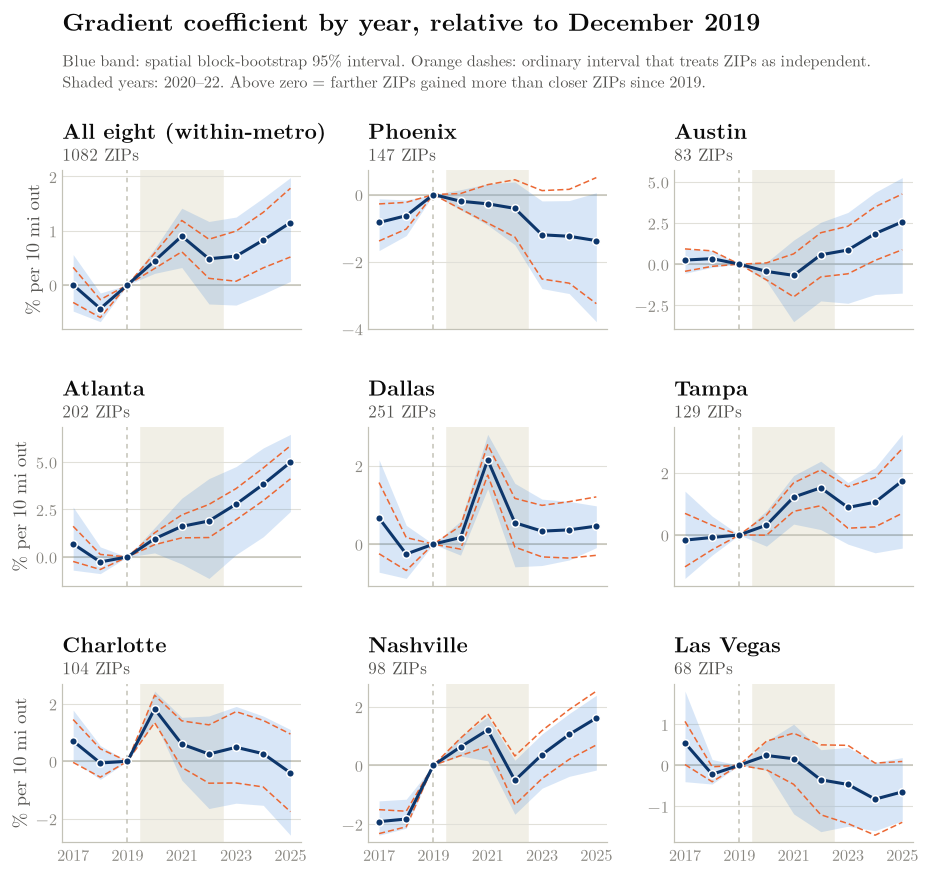

In [3]:
fig = VM.event_study_figure(tab); plt.show()

Are the event-study intervals lopsided? We compare the percentile interval with a basic (reverse-percentile) and a symmetric (estimate +/- 1.96 bootstrap SE)
interval from the same resamples, for 2022 and 2025.

In [4]:
t = tab.set_index(["scope", "year"])
ex = lambda lo, hi: bool(lo > 0 or hi < 0)
rows = []
for sc in summ["scope"]:
    for yr in (2022, 2025):
        r = t.loc[(sc, yr)]
        rows.append({"scope": sc, "year": yr, "estimate": round(r.beta, 2),
                     "percentile excludes 0": ex(r.boot_lo, r.boot_hi), "basic excludes 0": ex(r.basic_lo, r.basic_hi),
                     "symmetric excludes 0": ex(r.beta - 1.96 * r.boot_se, r.beta + 1.96 * r.boot_se)})
display(pd.DataFrame(rows))
x = tab[tab["year"] != 2019]
ratio = (x["boot_hi"] - x["beta"]) / (x["beta"] - x["boot_lo"])
print(f"upper side / lower side of the percentile interval: median {ratio.median():.2f}, range {ratio.min():.2f} to {ratio.max():.2f}")

,scope,year,estimate,percentile excludes 0,basic excludes 0,symmetric excludes 0
0,All eight (within-metro),2022,0.48,False,False,False
1,All eight (within-metro),2025,1.15,True,True,True
2,Phoenix,2022,-0.41,False,False,False
3,Phoenix,2025,-1.38,False,False,False
4,Austin,2022,0.57,False,False,False
5,Austin,2025,2.57,False,False,False
6,Atlanta,2022,1.89,False,False,False
7,Atlanta,2025,4.98,True,True,True
8,Dallas,2022,0.54,False,False,False
9,Dallas,2025,0.46,False,False,False


upper side / lower side of the percentile interval: median 0.80, range 0.43 to 2.15


**What it shows.** Pooled across the eight metros, the gradient widens after 2019 and keeps widening to 2025 (+1.15 per 10 miles by 2025, interval
0.07 to 1.98). That pooled result comes mostly from Atlanta (+4.98 by 2025, interval 2.40 to 6.46). Tampa is the only metro whose 2022 interval
excludes zero, and by 2025 it includes zero again. Phoenix drifts down. Charlotte, Dallas and Las Vegas end 2025 near zero. Nashville's 2017 and
2018 coefficients (about -1.9 and -1.8) show its outer ZIP codes were already gaining before the pandemic.
The last column is the ratio of the block-bootstrap width to the ordinary width: between 1.1 and 3.0. The ordinary intervals in our first report were
too narrow, as we suspected. The event-study intervals are only mildly lopsided (median upper/lower ratio 0.8, no consistent direction relative to zero). The pooled
and Atlanta results hold under all three interval types; Nashville (2025) and Tampa (2025) are the borderline cases that move.

## 2. Work-from-home exposure with a county random effect (SQ2)

Growth in a period regressed on the 2015-2019 work-from-home share (per 5 percentage points), with metro fixed effects and controls for distance,
income, home value in December 2019, detached-house share and the share of buildings with 20 or more units. We fit it four ways and compare the
coefficient on work-from-home share: OLS with robust errors, OLS with errors clustered by county, a mixed model with a county random intercept,
and OLS with a **spatial block bootstrap** interval (the same grid cells as in section 1, redrawn within each metro). Only the last one accounts for
spatial correlation; the other three are likely too narrow. The second set of rows adds each ZIP code's own pre-2020 growth as a control.

In [5]:
import io, contextlib
with contextlib.redirect_stderr(io.StringIO()):      # statsmodels prints optimizer notices that are not errors
    mm = M.mixed_model(xd)
display(mm[["outcome", "controls", "model", "wfh_per5pp", "se", "lo", "hi"]].round(3))
print("Four bootstrap intervals from the same resamples (lo/hi above for the bootstrap rows are BCa):")
bsr = mm[mm["model"] == "OLS, spatial block bootstrap"].copy()
bsr["asymmetry (upper side / lower side)"] = (bsr["pct_hi"] - bsr["wfh_per5pp"]) / (bsr["wfh_per5pp"] - bsr["pct_lo"])
display(bsr[["outcome", "controls", "wfh_per5pp", "se", "pct_lo", "pct_hi", "basic_lo", "basic_hi", "sym_lo", "sym_hi", "lo", "hi",
             "asymmetry (upper side / lower side)"]].rename(columns={"lo": "bca_lo", "hi": "bca_hi", "se": "boot_se"}).round(3))

,outcome,controls,model,wfh_per5pp,se,lo,hi
0,2020-22,controls,OLS (HC1),0.293,0.149,0.002,0.585
1,2020-22,controls,"OLS, clustered by county",0.293,0.125,0.048,0.539
2,2020-22,controls,Mixed (county random intercept),0.313,0.077,0.162,0.463
3,2020-22,controls + pre-2020 growth,OLS (HC1),0.256,0.137,-0.013,0.525
4,2020-22,controls + pre-2020 growth,"OLS, clustered by county",0.256,0.111,0.038,0.474
5,2020-22,controls + pre-2020 growth,Mixed (county random intercept),0.257,0.074,0.111,0.402
6,2023-25,controls,OLS (HC1),-0.347,0.100,-0.544,-0.150
7,2023-25,controls,"OLS, clustered by county",-0.347,0.113,-0.568,-0.126
8,2023-25,controls,Mixed (county random intercept),-0.145,0.071,-0.285,-0.005
9,2023-25,controls + pre-2020 growth,OLS (HC1),-0.320,0.095,-0.506,-0.133


Four bootstrap intervals from the same resamples (lo/hi above for the bootstrap rows are BCa):


,outcome,controls,wfh_per5pp,boot_se,pct_lo,pct_hi,basic_lo,basic_hi,sym_lo,sym_hi,bca_lo,bca_hi,asymmetry (upper side / lower side)
12,2020-22,controls,0.293,0.163,0.088,0.692,-0.106,0.499,-0.026,0.613,0.059,0.638,1.940
13,2020-22,controls + pre-2020 growth,0.256,0.151,0.070,0.629,-0.116,0.442,-0.040,0.553,0.044,0.577,2.003
14,2023-25,controls,-0.347,0.131,-0.698,-0.176,-0.517,0.004,-0.605,-0.089,-0.643,-0.127,0.486
15,2023-25,controls + pre-2020 growth,-0.320,0.123,-0.641,-0.152,-0.487,0.001,-0.560,-0.079,-0.581,-0.109,0.523


In [6]:
# Collinearity check: variance inflation factors for the controls (all below 5)
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
x = xd.dropna(subset=["log_income", "log_value19", "sfd_pct", "mf20_pct", "county_id"]).copy()
x["wfh5"], x["dist10"] = x["wfh_pct"] / 5, x["dist_nearest_mi"] / 10
cols = ["wfh5", "dist10", "log_income", "log_value19", "sfd_pct", "mf20_pct"]
X = pd.get_dummies(x[cols + ["metro_short"]], columns=["metro_short"], drop_first=True).astype(float)
X.insert(0, "const", 1.0)
print({c: round(vif(X.values, i), 2) for i, c in enumerate(X.columns) if c in cols})
print(f"{len(x):,} ZIP codes in {x['county_id'].nunique()} counties")

{'wfh5': np.float64(1.87), 'dist10': np.float64(1.43), 'log_income': np.float64(4.39), 'log_value19': np.float64(4.75), 'sfd_pct': np.float64(3.86), 'mf20_pct': np.float64(3.15)}
1,073 ZIP codes in 82 counties


**What it shows.** The sign of the work-from-home coefficient depends on what we hold fixed. With no controls (EDA) the within-metro slope was
-0.30 in 2020-22 and +0.40 in 2023-25. With income, home value and housing type held fixed it flips: about +0.29 in 2020-22 and -0.35 in 2023-25
under OLS. The bootstrap intervals are lopsided: the percentile intervals exclude zero in all four specifications, but the side away from zero is about twice as long as
the side toward it. A symmetric interval includes zero for both 2020-22 rows and a basic interval includes zero in all four (only just for 2023-25). The BCa interval, which corrects for this
bias and skew, excludes zero in all four, and it is the one we report. Because the 2020-22 verdict changes with the interval method, we do not treat that result as firm.
The mixed model's intervals are the narrowest, because it imposes a variance structure, and we do not count them as extra support. We do not read any of this as an effect of
remote work yet. It is the reason we plan an occupation-based exposure measure and interaction terms next.

## 3. Is there spatial correlation left? (Moran's I)

Moran's I compares each ZIP code's value with the average of its eight nearest ZIP codes. It is near 0 when neighbors are unrelated and positive
when similar values cluster. We test it against 999 random shuffles, for growth measured against the metro median and for the residuals of the control model.

In [7]:
mo = M.moran(xd, perms=999)
display(mo.round(3))

,period,variable,morans_I,p_value
0,pre-2020,growth minus metro median,0.445,0.001
1,pre-2020,residual after controls,0.350,0.001
2,2020-22,growth minus metro median,0.465,0.001
3,2020-22,residual after controls,0.351,0.001
4,2023-25,growth minus metro median,0.417,0.001
5,2023-25,residual after controls,0.375,0.001


Every value is clearly positive (0.35 to 0.47), and the controls only remove part of it. This is why we use block-bootstrap intervals
and why the prediction models below are always scored on a metro that was held out entirely.

## 4. Prediction models, scored on metros they have not seen

**Target:** annualized growth in a period minus the median growth of the ZIP code's own metro. **Features** come in four nested sets:
A (place and housing), B (+ income and professional jobs), C (+ work-from-home share), D (+ pre-2020 growth). Home value, income and pre-2020
growth are measured against the metro median. **Scoring:** leave one metro out. Train on seven metros (hyperparameters tuned by inner
grouped cross-validation), predict the eighth, repeat. Out-of-sample R-squared compares with always predicting the training average.
We also run an ordinary random 5-fold split to show how much it flatters the models.

In [8]:
x = M.ml_data(xd)
print(f"{len(x):,} ZIP codes, {x['metro_short'].nunique()} metros")
for k, v in M.FEATURE_SETS.items():
    print(k, "->", ", ".join(M.NICE[c] for c in v))

1,073 ZIP codes, 8 metros
A. Place and housing -> Miles from center, Home value, Dec 2019 (log, vs metro), Detached houses (%), Buildings with 20+ units (%), Population (log)
B. A + income and occupation -> Miles from center, Home value, Dec 2019 (log, vs metro), Detached houses (%), Buildings with 20+ units (%), Population (log), Household income (log, vs metro), Management/professional jobs (%)
C. B + work-from-home share -> Miles from center, Home value, Dec 2019 (log, vs metro), Detached houses (%), Buildings with 20+ units (%), Population (log), Household income (log, vs metro), Management/professional jobs (%), Work-from-home share (vs metro)
D. C + pre-2020 growth -> Miles from center, Home value, Dec 2019 (log, vs metro), Detached houses (%), Buildings with 20+ units (%), Population (log), Household income (log, vs metro), Management/professional jobs (%), Work-from-home share (vs metro), Growth before 2020 (vs metro)


One model, run live (ridge and random forest on all features, growth in 2023-25):

In [9]:
live, _, _ = M.ml_cv(x, "ann_cum_2022_2025_dm", sets=["D. C + pre-2020 growth"], models=["Ridge", "Random forest"])
display(live.round(3))

,features,model,target,RMSE,MAE,R2_leave_one_metro_out,R2_random_5fold,baseline_RMSE
0,D. C + pre-2020 growth,Ridge,ann_cum_2022_2025_dm,1.908,1.379,0.136,0.259,2.053
1,D. C + pre-2020 growth,Random forest,ann_cum_2022_2025_dm,1.907,1.357,0.138,0.337,2.053


In [10]:
if RUN_FULL_ML:
    parts = []
    for tg in ["ann_cum_2019_2022_dm", "ann_cum_2022_2025_dm"]:
        s, imp, _ = M.ml_cv(x, tg, perm_set="D. C + pre-2020 growth")
        parts.append(s)
        imp.to_csv(T / f"m_perm_importance_{tg}.csv", index=False)
    scores = pd.concat(parts); scores.to_csv(T / "m_cv_scores.csv", index=False)
else:
    scores = pd.read_csv(T / "m_cv_scores.csv")
show = scores[scores["features"].str.startswith("D")][["target", "model", "RMSE", "MAE", "R2_leave_one_metro_out", "R2_random_5fold", "baseline_RMSE"]]
display(show.round(3).reset_index(drop=True))

,target,model,RMSE,MAE,R2_leave_one_metro_out,R2_random_5fold,baseline_RMSE
0,ann_cum_2019_2022_dm,Ridge,1.966,1.398,0.253,0.344,2.274
1,ann_cum_2019_2022_dm,Lasso,2.033,1.441,0.200,0.342,2.274
2,ann_cum_2019_2022_dm,Random forest,2.059,1.431,0.180,0.455,2.274
3,ann_cum_2019_2022_dm,Gradient boosting,1.987,1.387,0.236,0.463,2.274
4,ann_cum_2022_2025_dm,Ridge,1.908,1.379,0.136,0.259,2.053
5,ann_cum_2022_2025_dm,Lasso,1.946,1.406,0.102,0.256,2.053
6,ann_cum_2022_2025_dm,Random forest,1.907,1.357,0.138,0.337,2.053
7,ann_cum_2022_2025_dm,Gradient boosting,1.905,1.343,0.139,0.316,2.053


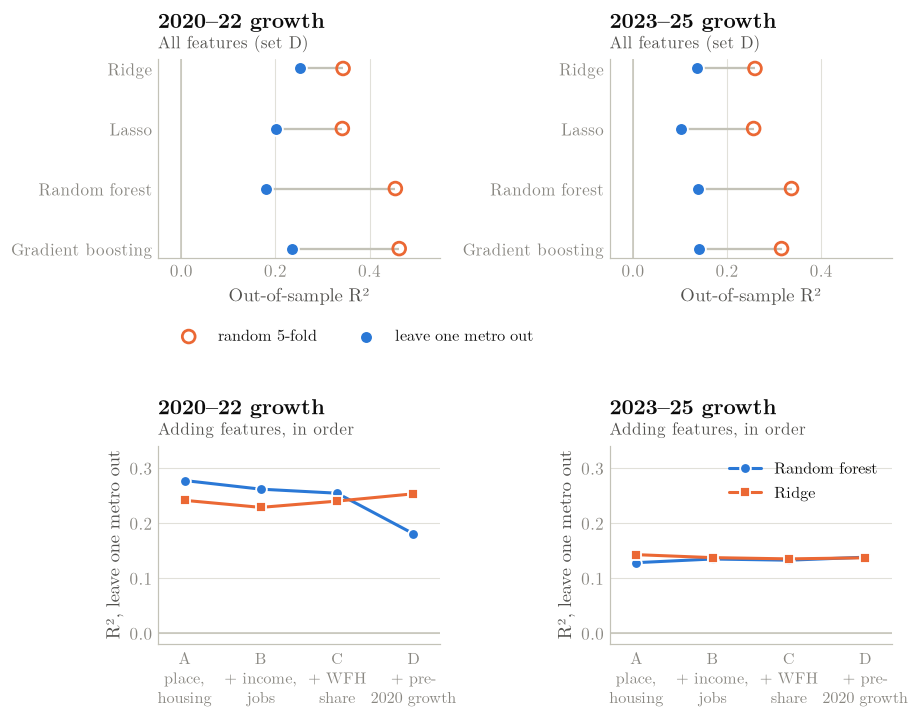

In [11]:
fig = VM.ml_figure(scores); plt.show()

In [12]:
# Does adding work-from-home share (set B -> set C) change the held-out score?
a = scores.pivot_table(index=["target", "model"], columns="features", values="R2_leave_one_metro_out")
a.columns = [c[0] for c in a.columns]
a["C minus B"] = a["C"] - a["B"]
display(a.round(3))

A      B      C      D  C minus B
target               model                                                   
ann_cum_2019_2022_dm Gradient boosting  0.271  0.278  0.295  0.236      0.016
                     Lasso              0.224  0.210  0.226  0.200      0.016
                     Random forest      0.277  0.261  0.254  0.180     -0.007
                     Ridge              0.241  0.228  0.239  0.253      0.011
ann_cum_2022_2025_dm Gradient boosting  0.140  0.111  0.097  0.139     -0.014
                     Lasso              0.118  0.119  0.119  0.102     -0.000
                     Random forest      0.128  0.134  0.132  0.138     -0.002
                     Ridge              0.142  0.137  0.135  0.136     -0.002

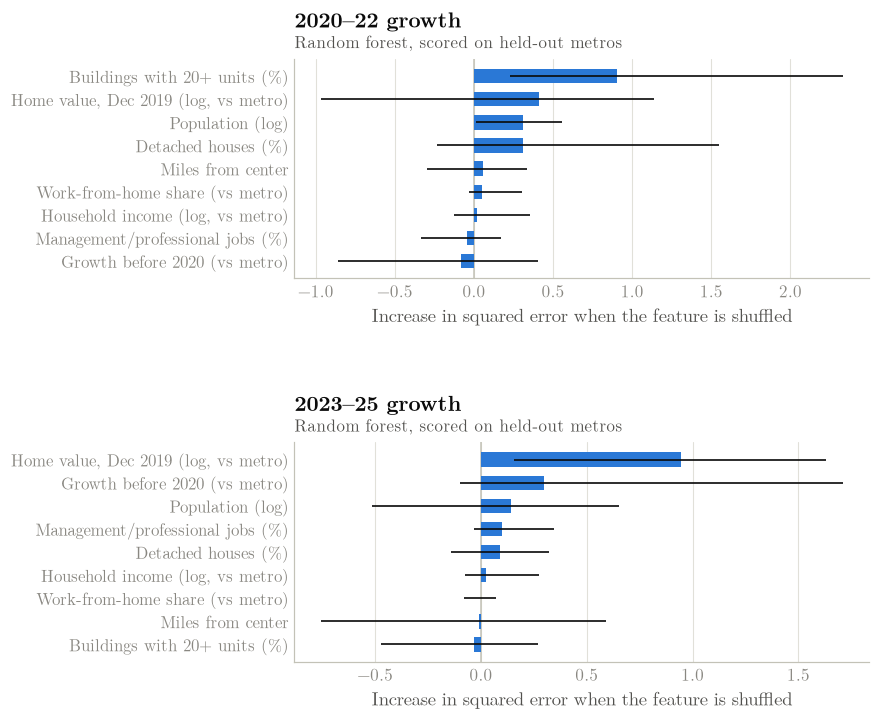

,2020–22 growth,2023–25 growth
Miles from center,-0.199,0.223
"Home value, Dec 2019 (log, vs metro)",-0.614,1.117
Detached houses (%),0.287,-0.150
Buildings with 20+ units (%),-0.610,-0.539
Population (log),0.377,-0.266
"Household income (log, vs metro)",0.433,-0.184
Management/professional jobs (%),-0.404,-0.138
Work-from-home share (vs metro),0.310,-0.175
Growth before 2020 (vs metro),0.411,-0.349


In [13]:
imps = {lab: pd.read_csv(T / f"m_perm_importance_{t}.csv")
        for t, lab in [("ann_cum_2019_2022_dm", "2020–22 growth"), ("ann_cum_2022_2025_dm", "2023–25 growth")]}
fig = VM.importance_figure(imps); plt.show()
display(pd.read_csv(T / "m_lasso_selection.csv", index_col=0).round(3))

**What it shows.** Predicting growth in a metro the model has never seen is hard. Held-out R-squared is 0.18 to 0.25 for 2020-22 and 0.10 to 0.14
for 2023-25 with all features, against 0.34 to 0.46 and 0.26 to 0.34 for the random split. The extra accuracy in a random split comes from
neighbors. Adding work-from-home share (set B to set C) changes the held-out score by no more than 0.02 for any model, and its permutation importance
is near zero. Place and housing features carry most of the weight. For the random forest on 2020-22 growth, adding pre-2020 growth lowers the held-out
score (0.25 to 0.18) while raising the random-split score. The importance whiskers are wide, so the ranking of the small features is not reliable.

## 5. Three ways to cluster the price paths (SQ3)

The input is each ZIP code's monthly index (December 2019 = 100) from January 2018 to December 2025, in logs. We compare k-means, Ward hierarchical
clustering and a Gaussian mixture (fit on the first five principal components), by silhouette width and by how much the methods agree (adjusted Rand index).

1,072 ZIP codes x 96 months;  variance in the first five components: [0.706 0.155 0.075 0.03  0.015]


method,Gaussian mixture,Ward hierarchical,k-means
k,,,
2,0.073,0.361,0.375
3,0.073,0.347,0.358
4,0.019,0.355,0.362
5,-0.014,0.255,0.282
6,0.008,0.259,0.276
7,0.009,0.258,0.275


,k,k-means vs Ward,k-means vs mixture,Ward vs mixture
0,2,0.808,0.019,0.013
1,3,0.808,0.037,0.042
2,4,0.788,0.161,0.163
3,5,0.623,0.152,0.159
4,6,0.594,0.188,0.261
5,7,0.694,0.250,0.247


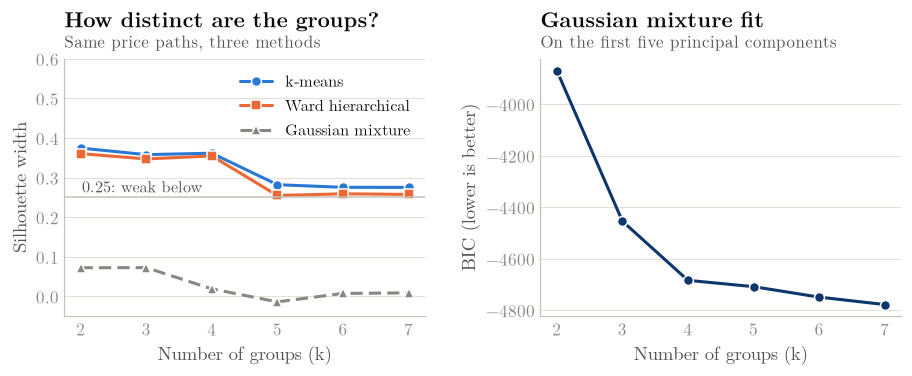

In [14]:
import viz_eda
panel = pd.read_parquet(ROOT / "data" / "clean" / "zhvi_analysis_panel.parquet", columns=["zip", "date", "index_dec2019"])
P = viz_eda.path_matrix(panel, gd)
ct, ari, evr = M.cluster_methods(P)
print(f"{P.shape[0]:,} ZIP codes x {P.shape[1]} months;  variance in the first five components: {np.round(evr, 3)}")
display(ct.pivot(index="k", columns="method", values="silhouette").round(3))
display(ari.round(3))
fig = VM.cluster_methods_figure(ct); plt.show()

**What it shows.** The first principal component holds 71% of the variation in the paths. k-means and Ward agree closely (ARI about 0.8 for k = 2 to 4) with silhouette widths of
0.35 to 0.37, falling below 0.3 at k = 5. The Gaussian mixture disagrees with both and has a silhouette near zero. The paths look like one smooth spread, not
separate clumps, so any grouping is a convenient slicing.

## Next
Monthly version of the event study, the two-center versions and the rent outcome; the occupation-based exposure score and exposure-by-distance
interactions; bootstrap stability and a multinomial model for the groups; soft-voting and stacked ensembles; a rerun without ZIP codes whose work-from-home estimate is unreliable.